# Image segmentation with K-means
In this notebook we will experiment with the k-means algorithm for image segmentation based on color similarity. The goal is to cluster the image pixels according to their color. We can visualize the pixels as points in a 3-dimensional space (since the color is a 3-d vector). In order for distances between colors to be perceptually meaningful, we work in the CIELAB color space.

In [1]:
%matplotlib inline
import matplotlib as mpl
mpl.rcParams['figure.dpi']=100
import numpy as np
from skimage.io import imread
from skimage.transform import rescale
from skimage.color import rgb2lab, lab2rgb
from sklearn.metrics.pairwise import euclidean_distances
import matplotlib.pyplot as plt
from mpl_toolkits import mplot3d

Load in an image, reshape it (to reduce the workload), and display it.

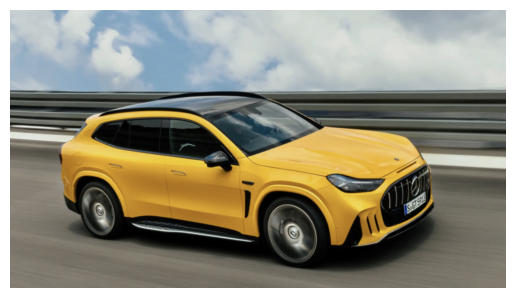

In [7]:
image_raw = imread('Skærmbillede 2026-10-21 kl. 16.44.30.png')[..., :3]
image_width = 1000
image = rescale(image_raw, image_width/image_raw.shape[0], mode='reflect', channel_axis=2, anti_aliasing=True)
shape = image.shape
plt.figure()
plt.imshow(image)
plt.axis('off');

Convert the image to a list of pixels in LAB-color space

In [8]:
image_pixels_lab = rgb2lab(image).reshape(-1,3)

Display a scatter plot of the image pixels, colored by their actual pixel color

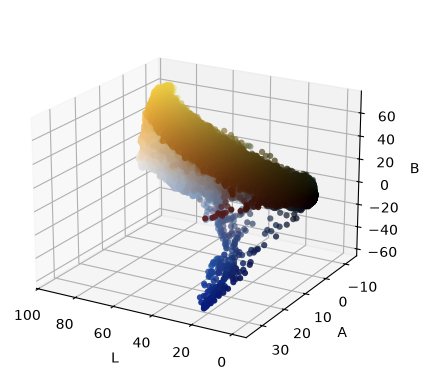

In [9]:
# Enable this to be able to rotate the scatter plot
# %matplotlib notebook 
plt.figure()
ax = plt.axes(projection='3d')
ax.view_init(elev=20., azim=120)
ax.set_xlabel("L")
ax.set_ylabel("A")
ax.set_zlabel("B")
image_c = [image.reshape(-1, 3)[i, :] for i in range(image.shape[0] * image.shape[1])]
ax.scatter3D(image_pixels_lab[:, 0], image_pixels_lab[:, 1], image_pixels_lab[:, 2], marker='o', c=image_c, linewidths=0);

Cluster the image pixels, treating colors as 3-dimensional points

In [10]:
# Define a plotting function
colors = ['r', 'g', 'b', 'c', 'm', 'y', 'k']
def plot_with_centers(image_pixels_lab, y, centers):
    plt.figure()
    ax = plt.axes(projection='3d')
    ax.view_init(elev=20., azim=120)
    ax.set_xlabel("L")
    ax.set_ylabel("A")
    ax.set_zlabel("B")
    ax.scatter3D(image_pixels_lab[:, 0], image_pixels_lab[:, 1], image_pixels_lab[:, 2], c=[colors[i % len(colors)] for i in y_kmeans], 
                 linewidths=0)
    ax.scatter3D(centers[:, 0], centers[:, 1], centers[:, 2], 
                 c=[colors[i % len(colors)] for i in range(K)], marker='+', s=200);

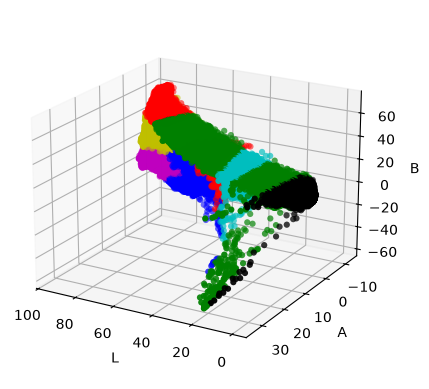

In [11]:
def cluster_assignments(X, Y):
    return np.argmin(euclidean_distances(X,Y), axis=1)

K = 10
centers = np.array([image_pixels_lab.mean(0) + (np.random.randn(3)/10) for _ in range(K)])
y_kmeans = cluster_assignments(image_pixels_lab, centers)

# repeat estimation a number of times (could do something smarter, like comparing if clusters change)
for i in range(30):
    # assign each point to the closest center
    y_kmeans = cluster_assignments(image_pixels_lab, centers)

    # move the centers to the mean of their assigned points (if any)
    for i, c in enumerate(centers):
        points = image_pixels_lab[y_kmeans == i]
        if len(points):
            centers[i] = points.mean(0)

plot_with_centers(image_pixels_lab, y_kmeans, centers)

Plot the result as an image, where each pixel is colored by its cluster mean

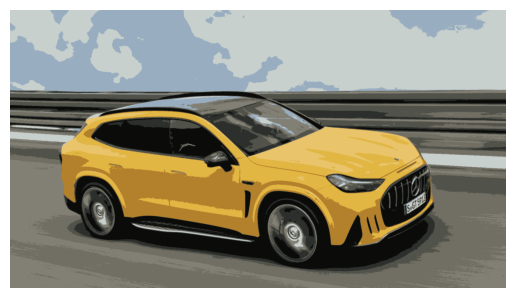

In [12]:
plt.figure()
plt.imshow(lab2rgb(centers[y_kmeans,:].reshape(shape[0], shape[1], 3)))
plt.axis('off');

Here is a littele experiment, where we change the color of one of the clusters by inverting the A-channels in the LAB color space. Since we don't know which cluster corresponds to which part of the image, try experimenting with which cluster index k to modify. If you hit the "grass" cluster, you should see red grass. 

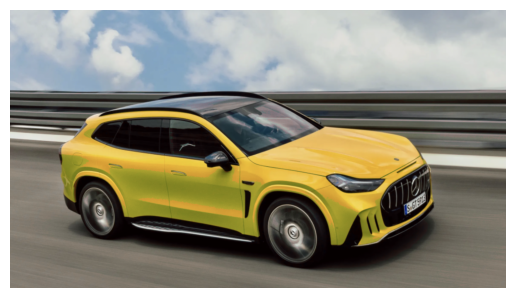

In [38]:
k = 8

plt.figure()
image_pixels_lab[y_kmeans==k, 1] = 2-image_pixels_lab[y_kmeans==k, 1] 
plt.imshow(lab2rgb(image_pixels_lab.reshape(shape)))
plt.axis('off');

$\star$ Experiment with increasing/decreasing the image resolution (image_width)

$\star$ Try out the different images **soccerball.jpg**, **roadsign.jpg**, **bananas.jpg**, **gates.jpg**

$\star$ Experiment with different values of K